# Exercise 3 — Deep-field depth and stacking

*Covers notebooks 01, 02. Difficulty: ★★☆☆☆*

Galaxy-evolution programs are planned in limiting magnitude: how deep does a field get per band for a given time, and what does it cost to build that time out of short frames?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

### 3.1 — Depth per filter

For a flat-spectrum (AB) point source, what 5 sigma depth does a single 300 s exposure reach in
zwo:u, g, r, i, z and bb?

In [2]:
def limiting_mag(sim, t, snr_target=5, mags=np.arange(16, 32.01, 0.25), **kw):
    """Magnitude at which the SNR in t seconds falls to snr_target; NaN if saturated or not bracketed."""
    r = sim.get_image_snr(t, mags=mags, warn=False, **kw)
    snr = np.where(r["saturated"], np.nan, r["snr"])
    ok = np.isfinite(snr)
    if ok.sum() < 2 or not (snr[ok].max() > snr_target > snr[ok].min()):
        return np.nan
    return float(np.interp(np.log10(snr_target), np.log10(snr[ok][::-1]), mags[ok][::-1]))

filters = ["zwo:u", "zwo:g", "zwo:r", "zwo:i", "zwo:z", "zwo:bb"]
sims = {f: Simulation.from_sensorfilter(f, get_scene("flat", mag=24, magsys="abmag")) for f in filters}
for f, s in sims.items():
    print(f"{f:7s}: 5 sigma in 300 s at AB = {limiting_mag(s, 300):.2f}")

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


zwo:u  : 5 sigma in 300 s at AB = 25.35
zwo:g  : 5 sigma in 300 s at AB = 27.71


zwo:r  : 5 sigma in 300 s at AB = 27.06
zwo:i  : 5 sigma in 300 s at AB = 25.99


zwo:z  : 5 sigma in 300 s at AB = 24.84
zwo:bb : 5 sigma in 300 s at AB = 28.03


> ✏️ **Before you run the next cell:** going from 300 s to 3000 s, does the g-band depth improve by 1.25 mag (sky limited), 2.5 mag (read-noise limited) or something in between? Write your guess down (or put it in the room poll), then run.

### 3.2 — Depth versus exposure time

Plot the 5 sigma depth against single-exposure time (30, 100, 300, 1000, 3000, 10000 s) for all six
filters. For g, compute the slope in magnitudes per decade between 30 and 300 s and between 3000
and 10000 s. The limits are 2.5 mag/decade (read-noise limited) and 1.25 (background limited):
which regime is the WCC in, and why does it change?

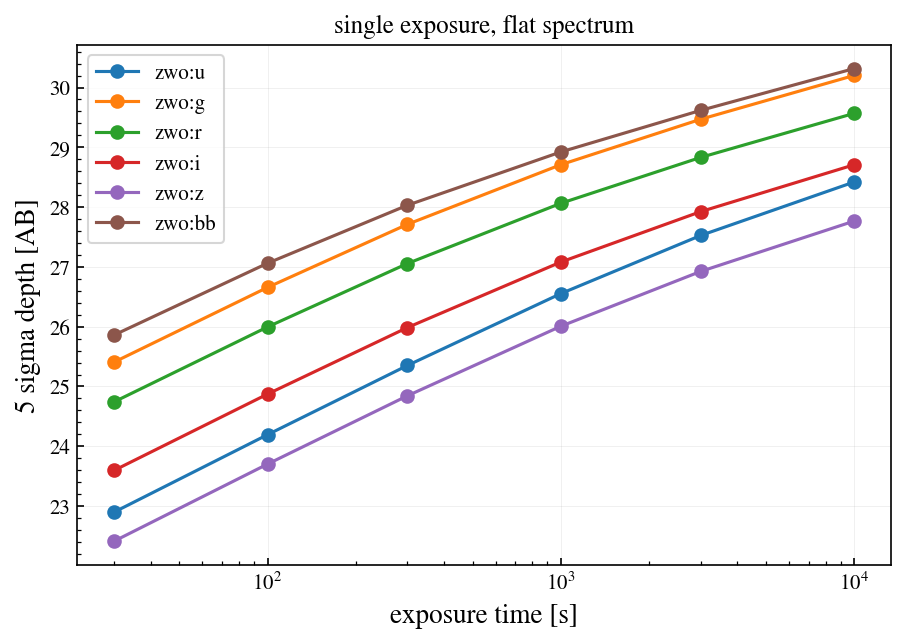

g: 2.30 mag/decade (30 -> 300 s), 1.40 mag/decade (3000 -> 10000 s)


In [3]:
exptimes = np.array([30, 100, 300, 1000, 3000, 10000])
depth = {f: np.array([limiting_mag(s, t) for t in exptimes]) for f, s in sims.items()}
fig, ax = plt.subplots(figsize=(7, 4.5))
for f in filters:
    ax.semilogx(exptimes, depth[f], "o-", label=f)
ax.set(xlabel="exposure time [s]", ylabel="5 sigma depth [AB]", title="single exposure, flat spectrum"); ax.legend()
plt.show()
slope = lambda f, i, j: (depth[f][j] - depth[f][i]) / np.log10(exptimes[j] / exptimes[i])
print(f"g: {slope('zwo:g', 0, 2):.2f} mag/decade (30 -> 300 s), {slope('zwo:g', 4, 5):.2f} mag/decade (3000 -> 10000 s)")
# The zodiacal sky is a few e-/pixel/minute: read noise dominates short frames, the sky only after ~1000 s.

### 3.3 — The cost of stacking

3000 s of r band taken as one frame, as 10 x 300 s, and as 100 x 30 s: what is the 5 sigma depth
of each stack? Why would anyone choose the shorter frames?

In [4]:
for n in (1, 10, 100):
    print(f"3000 s as {n:3d} x {3000 / n:5.0f} s: 5 sigma at AB = {limiting_mag(sims['zwo:r'], 3000, n_reads=n):.2f}")
# Saturation of the brightest stars in the field, cosmic rays, and dithering for detector defects.

3000 s as   1 x  3000 s: 5 sigma at AB = 28.83
3000 s as  10 x   300 s: 5 sigma at AB = 28.37
3000 s as 100 x    30 s: 5 sigma at AB = 27.35


### 3.4 — A real field

The field you want contains a G2V star of r = 15. What is the longest unsaturated single frame in
zwo:r (try 1, 2, 3, 5, 10, 20, 30, 60 s), and what 5 sigma depth does an hour of such frames reach?

In [5]:
bright = Simulation.from_sensorfilter("zwo:r", get_scene("G2V", mag=15, bandpass="sdss_r", magsys="abmag"))
frame = max(t for t in (1, 2, 3, 5, 10, 20, 30, 60) if not bright.is_saturated(t))
n = int(round(3600 / frame))
print(f"longest unsaturated frame: {frame} s -> {n} frames per hour; 5 sigma depth AB = {limiting_mag(sims['zwo:r'], 3600, n_reads=n):.2f} "
      f"(one 3600 s frame would give {limiting_mag(sims['zwo:r'], 3600):.2f})")

longest unsaturated frame: 3 s -> 1200 frames per hour; 5 sigma depth AB = 26.23 (one 3600 s frame would give 28.95)


> 🤖 **Ask Jupyter AI:** *The zodiacal background in wcc_etc is fixed at V = 22.5 mag/arcsec² but the Lazuli requirement value is 22.1. Rerun 3.1 with background_prop={'mag': 22.1} and report how much depth is lost in each filter.*
>
> Ask it, too, what else is missing from the noise model (hint: the wcc-etc README lists the known limitations).

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/wcc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*